# 02 · Clasificación de cancelaciones
Objetivo: predecir `is_canceled` con regresión logística y Random Forest, comparar modelos, seleccionar umbral y evaluar en test.

In [3]:
import sys
from pathlib import Path

# Add 'src' directory to python path if running from 'notebooks/'
src_path = Path('../src').resolve()
if str(src_path) not in sys.path:
    sys.path.append(str(src_path))

# Now import your functions safely
from pipeline import split_data, load_data, prepare, feature_columns, make_preprocessor

In [4]:
# Permite ejecutar el notebook desde VS Code o JupyterLab, en raíz o notebooks/
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').exists(), 'Abre la carpeta hotel_yield_ml como proyecto en VS Code.'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option('display.max_columns', 40)
from pipeline import load_data,prepare,split_data,feature_columns,make_preprocessor
from classification import metrics,threshold_table
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay,RocCurveDisplay,precision_recall_curve
from sklearn.model_selection import StratifiedKFold,cross_val_score
raw=load_data();df=prepare(raw)
train,val,test=split_data(df)
cols=feature_columns(df,'classification')
print('Train / val / test:',len(train),len(val),len(test))
print('Variables incluidas:',cols)

Train / val / test: 71634 23878 23878
Variables incluidas: ['hotel', 'lead_time', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'deposit_type', 'customer_type', 'arrival_month_num', 'total_nights', 'total_guests']


## 1 · Evitar data leakage
La etiqueta `is_canceled` y el estado final de la reserva no pueden formar parte de las entradas. Además se excluyen eventos posteriores como habitación asignada o cambios a la reserva. La ausencia de fecha real de creación de reserva limita una aplicación operativa estricta.

In [5]:
print('No deben aparecer:',[c for c in ['is_canceled','reservation_status','reservation_status_date','assigned_room_type','adr'] if c in cols])
X_train=train[cols]; X_val=val[cols]; X_test=test[cols]
y_train=train.is_canceled.astype(int);y_val=val.is_canceled.astype(int);y_test=test.is_canceled.astype(int)

No deben aparecer: []


## 2 · Preprocesamiento
`ColumnTransformer`: numéricas se imputan y escalan; categóricas se imputan y se convierten con OneHotEncoder. Todo queda dentro de Pipeline para aprender únicamente de train.

In [6]:
models={
 'Logistic Regression':Pipeline([('prep',make_preprocessor(X_train)),('model',LogisticRegression(solver='liblinear',C=1.0,max_iter=1000))]),
 'Random Forest':Pipeline([('prep',make_preprocessor(X_train)),('model',RandomForestClassifier(n_estimators=120,min_samples_leaf=8,random_state=1,n_jobs=-1))])
}
for name,model in models.items():
    model.fit(X_train,y_train)
    probs=model.predict_proba(X_val)[:,1]
    print(name,metrics(y_val,probs))

Logistic Regression {'auc': 0.8143191855626307, 'ap': 0.7855901233850782, 'accuracy': 0.7771170114749979, 'precision': 0.9006140550375256, 'recall': 0.44771057094403616, 'f1': 0.5980969642048029, 'threshold': 0.5, 'confusion_matrix': [[14596, 437], [4885, 3960]]}
Random Forest {'auc': 0.8656902205387453, 'ap': 0.8306818589294325, 'accuracy': 0.7892620822514449, 'precision': 0.8668462574562248, 'recall': 0.509327303561334, 'f1': 0.6416464891041163, 'threshold': 0.5, 'confusion_matrix': [[14341, 692], [4340, 4505]]}


## 3 · Evaluación: ROC-AUC
AUC evalúa capacidad de ordenar reservas por riesgo **independientemente del umbral**. Es útil, pero no sustituye precision/recall.

Ganador en validación: Random Forest


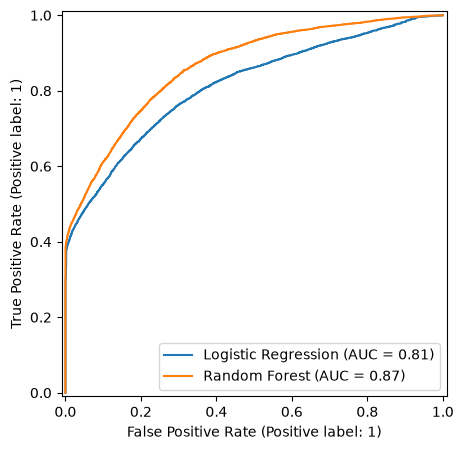

In [7]:
scores={name:metrics(y_val,model.predict_proba(X_val)[:,1]) for name,model in models.items()}
best_name=max(scores,key=lambda name:scores[name]['auc'])
print('Ganador en validación:',best_name)
fig,ax=plt.subplots(figsize=(7,5))
for name,model in models.items():
    RocCurveDisplay.from_predictions(y_val,model.predict_proba(X_val)[:,1],name=name,ax=ax)
plt.show()

## 4 · Precision, Recall, F1 y umbrales
Umbral pequeño => más alertas; umbral alto => menos alertas. Elegiremos el máximo F1 **en validación**. La curva de utilidad utiliza supuestos, no recuperaciones de ingresos observadas.

Umbral max F1: 0.37
Umbral escenario hipotético: 0.16


,threshold,f1,true_positives,false_positives,utility_proxy_usd
32,0.37,0.718893,6910,3469,549135.0
31,0.36,0.717891,7026,3703,555717.0
30,0.35,0.717612,7151,3934,563127.0
33,0.38,0.717514,6764,3245,539793.0
29,0.34,0.717308,7257,4132,569379.0
28,0.33,0.717112,7359,4320,575433.0
34,0.39,0.715984,6625,3036,530835.0
27,0.32,0.715323,7439,4515,579468.0
35,0.40,0.715107,6466,2773,520947.0
26,0.31,0.714823,7511,4659,583572.0


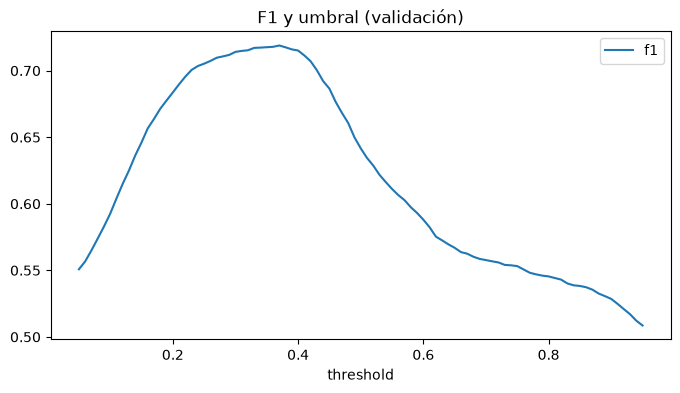

{'auc': 0.8656902205387453, 'ap': 0.8306818589294325, 'accuracy': 0.7736828880140715, 'precision': 0.6657674149725407, 'recall': 0.781232334652346, 'f1': 0.7188930503537245, 'threshold': 0.37, 'confusion_matrix': [[11564, 3469], [1935, 6910]]}


In [11]:
p_val = models[best_name].predict_proba(X_val)[:, 1]
thresholds = threshold_table(y_val, p_val)
best_t = float(thresholds.loc[thresholds.f1.idxmax(), 'threshold'])
best_business_t = float(thresholds.loc[thresholds.utility_proxy_usd.idxmax(), 'threshold'])

# Corrección de las comillas y separación en dos prints (o usando un f-string)
print('Umbral max F1:', best_t)
print('Umbral escenario hipotético:', best_business_t)

display(thresholds.sort_values('f1', ascending=False).head(10))
thresholds.plot(x='threshold', y='f1', figsize=(8, 4), title='F1 y umbral (validación)')
plt.show()

print(metrics(y_val, p_val, best_t))

## 5 · Matriz de confusión
Filas = clase real, columnas = clase predicha. **FP** significa molestar a una reserva que no se cancelaría; **FN** significa perder la oportunidad de intervenir una cancelación.

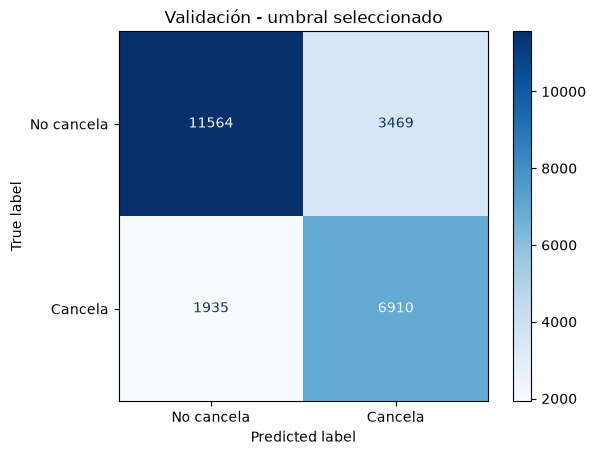

In [12]:
ConfusionMatrixDisplay.from_predictions(y_val,p_val>=best_t,display_labels=['No cancela','Cancela'],cmap='Blues')
plt.title('Validación - umbral seleccionado');plt.show()

## 6 · Evaluación final (test) y modelo reutilizable
Para no contaminar el test, finalizamos selección de modelo y umbral con validación, reentrenamos en train+val y aplicamos al test **una sola vez**.

In [14]:
from classification import run
resultados,tabla_umbral,modelo_final=run()
print('MODELO:',resultados['selected_model'])
print('TEST (único):',resultados['test'])

logistic {'auc': 0.814, 'ap': 0.786, 'precision': 0.901, 'recall': 0.448, 'f1': 0.598}
random_forest {'auc': 0.866, 'ap': 0.831, 'precision': 0.867, 'recall': 0.509, 'f1': 0.642}
MODELO: random_forest
TEST (único): {'auc': 0.8664009162882923, 'ap': 0.8326128197430498, 'accuracy': 0.7684060641594773, 'precision': 0.6596974660371905, 'recall': 0.7741096664782363, 'f1': 0.7123387432376196, 'threshold': 0.37, 'confusion_matrix': [[11501, 3532], [1998, 6847]]}


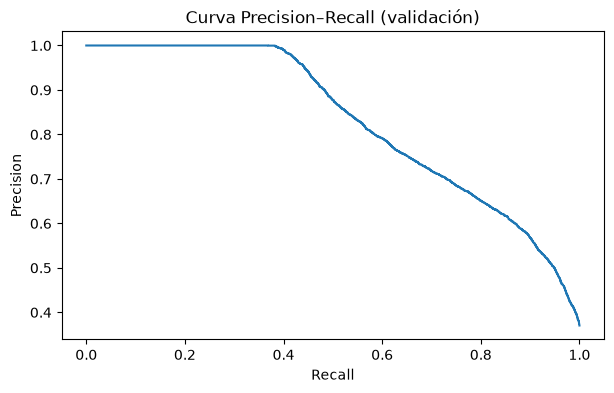

In [15]:
from sklearn.metrics import precision_recall_curve
pr,rc,_=precision_recall_curve(y_val,p_val)
fig,ax=plt.subplots(figsize=(7,4));ax.plot(rc,pr)
ax.set(xlabel='Recall',ylabel='Precision',title='Curva Precision–Recall (validación)');plt.show()


## 7 · Validación cruzada (5-Fold)
Dividimos **solo el entrenamiento** en 5 partes; en cada vuelta se ajusta imputación, codificación y el clasificador sin mirar el fold de evaluación. Esto ayuda a evaluar estabilidad del modelo. No elegimos umbrales usando el test.

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
logit_cv=Pipeline([('prep',make_preprocessor(X_train)),('model',LogisticRegression(solver='liblinear',C=1.0,max_iter=1000))])
auc_scores=cross_val_score(logit_cv,X_train,y_train,cv=cv,scoring='roc_auc',n_jobs=-1)
print('AUC por fold:',np.round(auc_scores,3))
print('Media:',round(auc_scores.mean(),3),'Desv. estándar:',round(auc_scores.std(),3))


AUC por fold: [0.809 0.811 0.815 0.807 0.811]
Media: 0.811 Desv. estándar: 0.003
